# Módulo 3: Agentes de IA
- **Sesión:** 03 — Sistemas multiagente, orquestación y workflows complejos


## Fundamentos

Un **sistema multiagente** reparte una tarea entre varios agentes especializados. La **orquestación** define cómo se coordinan.

| Caso | Concepto | Idea central |
|---|---|---|
| 1 | Agentes especializados | Cada agente atiende una sola área |
| 2 | Supervisor | Un agente principal delega en los agentes especializados |
| 3 | Enrutador | El código envía la consulta a un solo agente |
| 4 | Ejecución en paralelo | Dos tareas independientes al mismo tiempo |
| 5 | Evaluador-optimizador | Se redacta y se evalúa hasta cumplir, con límite de intentos |
| 6 | Integración | Enrutador y supervisor en un mismo sistema |

## Configuración

In [2]:
from langchain.tools import tool
from langchain.chat_models import init_chat_model

from dotenv import load_dotenv
import os
import logging

logging.getLogger("google_genai.models").setLevel(logging.ERROR)

from langchain.tools import tool


In [3]:
# Generar una funcion que obtenga el modelo LLM

def get_llm(prefix_model, temperature=0.9):
    """
    Obtiene un modelo de lenguaje (LLM) basado en el modelo especificado.

    Args:
        model (str): El nombre del modelo a utilizar.
        temperature (float, optional): La temperatura para la generación de texto. 
                                        Valores más altos producen respuestas más creativas.
                                        Valores más bajos producen respuestas más deterministas.
                                        Por defecto es 0.9.

    Returns:
        llm: Un objeto de modelo de lenguaje inicializado.
    """
    llm = init_chat_model(
                            model=prefix_model, 
                            # temperature=temperature
                          )
    return llm

# Configuración del modelo de lenguaje
load_dotenv(override = True)

prefix_model = os.getenv("PREFIX_MODEL")

# Obtención del modelo
llm = get_llm(prefix_model)


In [4]:
# Datos simulados de TiendaYa
PEDIDOS = {
    "48213": "en ruta, llega el 18/11/2026 a Arequipa",
    "50555": "en preparación, llega el 21/11/2026 a Cusco",
}

POLITICAS = {
    "devoluciones": "15 días calendario desde la entrega.",
    "envios": "Envío gratuito desde S/ 150.",
}


@tool
def consultar_pedido(numero_pedido: str) -> str:
    """
    Consulta el estado de un pedido de TiendaYa."""
    return PEDIDOS.get(numero_pedido, "No existe ese pedido.")


@tool
def consultar_politica(tema: str) -> str:
    """
    Devuelve la política de TiendaYa sobre 'devoluciones' o 'envios'.
    """
    return POLITICAS.get(tema.lower(), "No existe esa política.")


def preguntar(agente, texto: str) -> str:
    """
    Envía un mensaje a un agente y devuelve su respuesta final.
    """
    resultado = agente.invoke({"messages": [{"role": "user", 
                                             "content": texto}]})
    return resultado["messages"][-1].text


def ver_grafo(app):
    """
    Muestra el diagrama del grafo; si no hay conexión, lo imprime en formato Mermaid.
    """
    try:
        from IPython.display import Image, display
        display(Image(app.get_graph().draw_mermaid_png()))
    except Exception:
        print(app.get_graph().draw_mermaid())

---
## Caso 1 — Agentes especializados

### Concepto
Un agente único con muchas tareas pierde precisión. Por eso el trabajo se reparte: cada **agente especializado** atiende una sola área, con sus propias instrucciones y herramientas.

| Agente | Instrucciones | Herramienta |
|---|---|---|
| Agente de pedidos | Solo responde sobre pedidos | `consultar_pedido` |
| Agente de políticas | Solo responde sobre devoluciones y envíos | `consultar_politica` |

### Ejecutar

In [5]:
from langchain.agents import create_agent

agente_pedidos = create_agent(
    model=llm,
    tools=[consultar_pedido],
    system_prompt="Eres el agente de pedidos de TiendaYa. Solo respondes sobre pedidos.",
)

agente_politicas = create_agent(
    model=llm,
    tools=[consultar_politica],
    system_prompt="Eres el agente de políticas de TiendaYa. Solo respondes sobre devoluciones y envíos.",
)

In [6]:
print("Agente de pedidos  :", preguntar(agente_pedidos, "¿Dónde está mi pedido 48213?"))
print("Agente de políticas:", preguntar(agente_politicas, "¿Cuántos días tengo para devolver un producto?"))

Agente de pedidos  : Tu pedido 48213 se encuentra actualmente **en ruta** y está programado para llegar el **18/11/2026** a Arequipa.
Agente de políticas: Tienes **15 días calendario** desde la fecha de entrega para devolver un producto.



### Práctica
Preguntar al agente de pedidos *«¿Cuántos días tengo para devolver un producto?»* y observar su respuesta.

In [7]:
print("Agente de pedidos  :", preguntar(agente_pedidos, "¿Cuántos días tengo para devolver un producto?"))


Agente de pedidos  : Como agente de pedidos de TiendaYa, solo puedo ayudarte con consultas relacionadas con el estado y seguimiento de tus pedidos. 

Para dudas sobre devoluciones, te sugiero revisar la sección de políticas de devolución en nuestro sitio web o contactar al servicio de atención al cliente general. 

¿Te puedo ayudar con el estado de algún número de pedido?


---
## Caso 2 — Patrón supervisor

### Concepto
El **supervisor** es un agente que no tiene datos propios: recibe la consulta y la **delega** en los agentes especializados. Para el supervisor, cada agente especializado es una **herramienta**.

```
                     ┌──▶ area_pedidos   (agente de pedidos)
Consulta ──▶ SUPERVISOR
                     └──▶ area_politicas (agente de políticas)
```

### Ejecutar

In [10]:
from langchain.agents import create_agent
from langchain.tools import tool


@tool
def area_pedidos(consulta: str) -> str:
    """
        Responde consultas sobre el estado de un pedido.
    """
    return preguntar(agente_pedidos, consulta)


@tool
def area_politicas(consulta: str) -> str:
    """
        Responde consultas sobre devoluciones y envíos.
    """
    return preguntar(agente_politicas, consulta)


supervisor = create_agent(
    model=llm,
    tools=[area_pedidos, area_politicas],
    system_prompt="""
                    Eres el supervisor de TiendaYa. Delega cada parte de la consulta 
                    en el área correcta y une las respuestas en un unico mensaje.
                  """,
)

In [11]:
consulta = "¿Dónde está mi pedido 50555 y cuántos días tengo para devolverlo?"
resultado = supervisor.invoke({"messages": [{"role": "user", "content": consulta}]})

for mensaje in resultado["messages"]:
    for llamada in getattr(mensaje, "tool_calls", []) or []:
        print("El supervisor delega en:", llamada["name"])

print("Respuesta final:", resultado["messages"][-1].text)

El supervisor delega en: area_pedidos
El supervisor delega en: area_politicas
Respuesta final: El estado de tu pedido 50555 es el siguiente: se encuentra actualmente en preparación y está programado para llegar el 21/11/2026 a Cusco. 

Respecto a tu consulta sobre devoluciones, tienes 15 días calendario desde la fecha de entrega para realizar cualquier cambio o devolución.


### Aspectos para observar
- Con la consulta compuesta, el supervisor delega en las **dos** áreas.
- El supervisor elige el área leyendo el docstring de cada herramienta.

### Práctica
Probar el supervisor con *«¿El envío es gratuito?»* y comprobar que delega en una sola área.

---
## Caso 3 — Patrón enrutador

### Concepto
En el **enrutador**, el modelo solo clasifica la consulta y una **arista condicional** la envía a un solo agente. El camino lo decide el código.

```
                      ┌─(pedido)───▶ atender_pedido ───┐
START ──▶ clasificar ─┤                                ├──▶ END
                      └─(politica)─▶ atender_politica ─┘
```

| | Supervisor | Enrutador |
|---|---|---|
| Quién decide | El modelo | El código |
| Áreas por consulta | Una o varias | Una sola |

### Ejecutar

In [12]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class Estado(TypedDict):
    consulta: str
    area: str
    respuesta: str


def clasificar(estado: Estado) -> dict:
    """El modelo indica el área de la consulta."""
    area = llm.invoke("¿La consulta trata de PEDIDO o de POLITICA? Responde solo una palabra.\n"
                      f"Consulta: {estado['consulta']}").text.upper()
    return {"area": area}


def atender_pedido(estado: Estado) -> dict:
    """Entrega la consulta al agente de pedidos."""
    return {"respuesta": preguntar(agente_pedidos, estado["consulta"])}


def atender_politica(estado: Estado) -> dict:
    """Entrega la consulta al agente de políticas."""
    return {"respuesta": preguntar(agente_politicas, estado["consulta"])}


def elegir(estado: Estado) -> str:
    """Elige el camino según el área."""
    return "pedido" if "PEDIDO" in estado["area"] else "politica"


grafo = StateGraph(Estado)
grafo.add_node("clasificar", clasificar)
grafo.add_node("atender_pedido", atender_pedido)
grafo.add_node("atender_politica", atender_politica)
grafo.add_edge(START, "clasificar")
grafo.add_conditional_edges("clasificar", elegir, {"pedido": "atender_pedido", "politica": "atender_politica"})
grafo.add_edge("atender_pedido", END)
grafo.add_edge("atender_politica", END)
enrutador = grafo.compile()

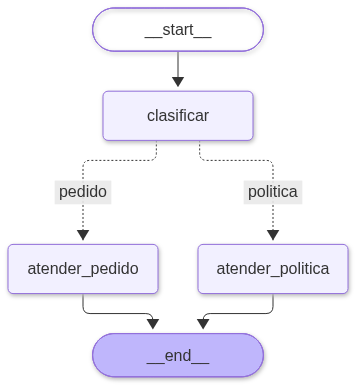

In [13]:
ver_grafo(enrutador)

In [14]:
for consulta in ["¿Dónde está mi pedido 48213?", "¿El envío es gratuito?"]:
    resultado = enrutador.invoke({"consulta": consulta})
    print(f"{consulta}\n  área: {resultado['area']}\n  -> {resultado['respuesta']}\n")

¿Dónde está mi pedido 48213?
  área: PEDIDO
  -> Tu pedido 48213 actualmente está en ruta y se tiene previsto que llegue el 18/11/2026 a Arequipa.

¿El envío es gratuito?
  área: POLITICA
  -> El envío es gratuito a partir de compras de S/ 150.



### Aspectos para observar
- Cada consulta sigue un solo camino.
- El estado guarda el área elegida y la respuesta.

### Práctica
Probar el enrutador con la consulta compuesta *«¿Dónde está mi pedido 50555 y cuántos días tengo para devolverlo?»* y observar que solo responde una parte.

# Ejercicio

Crear la funcion antender_inventario que debe usar un agente llamado agente_inventario

|Producto|	Unidades	|Precio|
|-|-|-|
|licuadora|	5	|S/ 189.00|
|audifonos|	0	|S/ 129.00|
|zapatillas	|12	|S/ 249.00|

E incluirlo en el enrutador


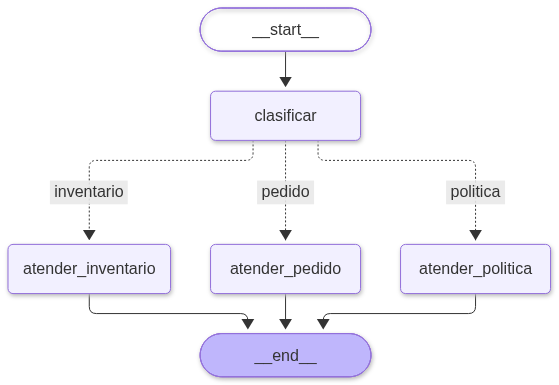

In [15]:

# Defino las herramientas

INVENTARIO = {
    "licuadora": {"unidad": 5, "precio": 189},
    "audifonos": {"unidad": 0, "precio": 129},
    "zapatillas": {"unidad": 12, "precio": 249},
}


@tool
def consultar_inventario(producto: str) -> dict:
    """
    Consulta el inventario de un producto en TiendaYa."""
    return INVENTARIO.get(producto, {"unidad": 0, "precio": 0})

# Defino el agente de inventario
agente_inventario = create_agent(
    model=llm,
    tools=[consultar_inventario],
    system_prompt="Eres el agente de inventario de TiendaYa. Solo respondes sobre la cantidad y precio de los productos."
)

# defino la función de atención de inventario


def clasificar(estado: Estado) -> dict:
    """El modelo indica el área de la consulta."""
    area = llm.invoke("¿La consulta trata de PEDIDO, INVENTARIO o de POLITICA? Responde solo una palabra.\n"
                      f"Consulta: {estado['consulta']}").text.upper()
    return {"area": area}


def atender_inventario(estado: Estado) -> dict:
    """Entrega la consulta al agente de inventario."""
    return {"respuesta": preguntar(agente_inventario, estado["consulta"])}


def elegir(estado: Estado) -> str:
    """Elige el camino según el área."""
    return "pedido" if "PEDIDO" in estado["area"] else "inventario" if "INVENTARIO" in estado["area"] else "politica"


grafo = StateGraph(Estado)
grafo.add_node("clasificar", clasificar)
grafo.add_node("atender_inventario", atender_inventario)
grafo.add_node("atender_pedido", atender_pedido)
grafo.add_node("atender_politica", atender_politica)
grafo.add_edge(START, "clasificar")
grafo.add_conditional_edges("clasificar", elegir, {"pedido": "atender_pedido", "inventario": "atender_inventario", "politica": "atender_politica"})
grafo.add_edge("atender_pedido", END)
grafo.add_edge("atender_inventario", END)
grafo.add_edge("atender_politica", END)
enrutador = grafo.compile()

ver_grafo(enrutador)

In [16]:
for consulta in ["¿Dónde está mi pedido 48213?", "¿El envío es gratuito?", "¿Cuántas zapatillas hay en stock?"]:
    resultado = enrutador.invoke({"consulta": consulta})
    print(f"{consulta}\n  área: {resultado['area']}\n  -> {resultado['respuesta']}\n")

¿Dónde está mi pedido 48213?
  área: PEDIDO
  -> Tu pedido 48213 se encuentra actualmente **en ruta** y está programado para llegar el **18/11/2026** a Arequipa.

¿El envío es gratuito?
  área: POLITICA
  -> El envío es gratuito a partir de compras de S/ 150.

¿Cuántas zapatillas hay en stock?
  área: INVENTARIO
  -> Tenemos 12 zapatillas en stock y su precio es de $249 cada una.



---
## Caso 4 — Ejecución en paralelo

### Concepto
Cuando dos tareas son **independientes**, se ejecutan al mismo tiempo. Un nodo final **une** los resultados.

```
            ┌──▶ analizar_tono ────┐
START ──────┤                      ├──▶ unir ──▶ END
            └──▶ evaluar_urgencia ─┘
```

- Dos aristas desde `START` inician las dos ramas a la vez.
- `add_edge([rama1, rama2], "unir")` hace que `unir` espere a las dos ramas.

### Ejecutar

In [17]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class Estado(TypedDict):
    resena: str
    tono: str
    urgencia: str
    resumen: str


def analizar_tono(estado: Estado) -> dict:
    """El modelo indica el tono de la reseña."""
    tono = llm.invoke(f"Tono de esta reseña en una palabra (POSITIVO o NEGATIVO): {estado['resena']}").text
    return {"tono": tono.strip()}


def evaluar_urgencia(estado: Estado) -> dict:
    """El modelo indica la urgencia de atención."""
    urgencia = llm.invoke(f"Urgencia de esta reseña en una palabra (ALTA o BAJA): {estado['resena']}").text
    return {"urgencia": urgencia.strip()}


def unir(estado: Estado) -> dict:
    """Une los dos resultados en un resumen."""
    return {"resumen": f"Tono: {estado['tono']} | Urgencia: {estado['urgencia']}"}


grafo = StateGraph(Estado)
grafo.add_node("analizar_tono", analizar_tono)
grafo.add_node("evaluar_urgencia", evaluar_urgencia)
grafo.add_node("unir", unir)

grafo.add_edge(START, "analizar_tono")                        # rama 1
grafo.add_edge(START, "evaluar_urgencia")                     # rama 2
grafo.add_edge(["analizar_tono", "evaluar_urgencia"], "unir") # espera a las dos ramas
grafo.add_edge("unir", END)
analizador = grafo.compile()

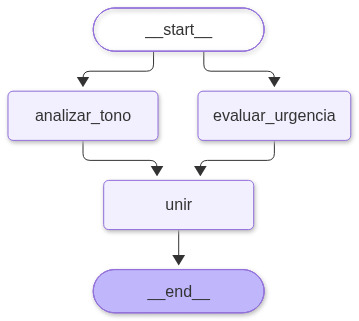

In [18]:
ver_grafo(analizador)

In [23]:
resena = "Mi licuadora llegó rota y la necesito antes del sábado."

# Seguimiento de la ejecución del grafo en tiempo real
for paso in analizador.stream({"resena": resena}, stream_mode="updates"):
    print("Terminó el nodo:", list(paso)[0])

# La ejecución final del grafo devuelve el resumen
print(analizador.invoke({"resena": resena})["resumen"])

Terminó el nodo: evaluar_urgencia
Terminó el nodo: analizar_tono
Terminó el nodo: unir
Tono: NEGATIVO | Urgencia: ALTA


### Aspectos para observar
- `stream` muestra que las dos ramas terminan antes de `unir`.
- Cada rama escribe una clave distinta del estado.

### Práctica
Agregar una tercera rama, `identificar_producto`, que devuelva el nombre del producto, e incluirla en el resumen.

---
## Caso 5 — Patrón evaluador-optimizador

### Concepto
Un nodo **redacta** el mensaje y una función lo **evalúa**. Si no cumple el criterio, se redacta de nuevo. Un **límite de intentos** evita que el ciclo se repita sin fin.

```
START ──▶ redactar ──(cumple o límite)──▶ END
             ▲   │
             └───┘ (no cumple)
```

Criterio de evaluación: el mensaje tiene como máximo `MAX_PALABRAS` palabras. Lo verifica el código.

### Ejecutar

In [24]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

MAX_PALABRAS = 20
MAX_INTENTOS = 3


class Estado(TypedDict):
    dato: str
    texto: str
    intentos: int


def redactar(estado: Estado) -> dict:
    """El modelo redacta el mensaje y se cuenta el intento."""
    texto = llm.invoke(f"Escribe un mensaje cordial para el cliente con este dato, "
                       f"en máximo {MAX_PALABRAS} palabras: {estado['dato']}").text
    return {"texto": texto, "intentos": estado["intentos"] + 1}


def evaluar(estado: Estado) -> str:
    """Evalúa el mensaje con código: cuenta las palabras."""
    palabras = len(estado["texto"].split())
    print(f"Intento {estado['intentos']}: {palabras} palabras")
    if palabras <= MAX_PALABRAS or estado["intentos"] >= MAX_INTENTOS:
        return "terminar"
    return "repetir"


grafo = StateGraph(Estado)
grafo.add_node("redactar", redactar)
grafo.add_edge(START, "redactar")
grafo.add_conditional_edges("redactar", evaluar, {"terminar": END, "repetir": "redactar"})
redactor = grafo.compile()

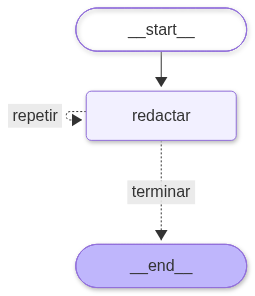

In [25]:
ver_grafo(redactor)

In [28]:
resultado = redactor.invoke({"dato": "Pedido 48213: en ruta, llega el 18/11/2026 a Arequipa",
                             "intentos": 1})
print("Mensaje final:", resultado["texto"])

Intento 2: 17 palabras
Mensaje final: ¡Hola! Tu pedido 48213 está en ruta y llegará a Arequipa el 18/11/2026. ¡Gracias por tu compra!


### Aspectos para observar
- El estado guarda el número de intentos.
- El ciclo termina cuando el mensaje cumple o cuando se llega a `MAX_INTENTOS`.

### Práctica
Cambiar `MAX_PALABRAS` a `8`, volver a ejecutar el caso y observar cuántos intentos se realizan.

---
## Caso 6 — Integración

### Concepto
Se combinan los patrones: el **enrutador** envía las consultas simples a un agente especializado, y las consultas que mezclan áreas al **supervisor**.

```
                      ┌─(pedido)───▶ atender_pedido ───┐
START ──▶ clasificar ─┼─(politica)─▶ atender_politica ─┼──▶ END
                      └─(varios)───▶ atender_varios ───┘
                                      (supervisor)
```

### Ejecutar

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class Estado(TypedDict):
    consulta: str
    area: str
    respuesta: str


def clasificar(estado: Estado) -> dict:
    """El modelo indica el área de la consulta."""
    area = llm.invoke("Responde una palabra: PEDIDO (solo pedido), POLITICA (solo política) "
                      "o VARIOS (pedido y política).\n"
                      f"Consulta: {estado['consulta']}").text.upper()
    return {"area": area}


def atender_pedido(estado: Estado) -> dict:
    """Entrega la consulta al agente de pedidos."""
    return {"respuesta": preguntar(agente_pedidos, estado["consulta"])}


def atender_politica(estado: Estado) -> dict:
    """Entrega la consulta al agente de políticas."""
    return {"respuesta": preguntar(agente_politicas, estado["consulta"])}


def atender_varios(estado: Estado) -> dict:
    """Entrega la consulta al supervisor."""
    return {"respuesta": preguntar(supervisor, estado["consulta"])}


def elegir(estado: Estado) -> str:
    """Elige el camino según el área."""
    if "VARIOS" in estado["area"]:
        return "varios"
    return "pedido" if "PEDIDO" in estado["area"] else "politica"


grafo = StateGraph(Estado)
grafo.add_node("clasificar", clasificar)
grafo.add_node("atender_pedido", atender_pedido)
grafo.add_node("atender_politica", atender_politica)
grafo.add_node("atender_varios", atender_varios)
grafo.add_edge(START, "clasificar")
grafo.add_conditional_edges("clasificar", elegir,
                            {"pedido": "atender_pedido", "politica": "atender_politica", "varios": "atender_varios"})
grafo.add_edge("atender_pedido", END)
grafo.add_edge("atender_politica", END)
grafo.add_edge("atender_varios", END)
sistema = grafo.compile()

In [ ]:
ver_grafo(sistema)

In [ ]:
consultas = ["¿Dónde está mi pedido 48213?",
             "¿El envío es gratuito?",
             "¿Dónde está mi pedido 50555 y cuántos días tengo para devolverlo?"]
for consulta in consultas:
    recorrido = [list(paso)[0] for paso in sistema.stream({"consulta": consulta}, stream_mode="updates")]
    print(f"{consulta}\n  recorrido: {' → '.join(recorrido)}\n")

### Aspectos para observar
- Las consultas simples no usan el supervisor.
- Solo la consulta compuesta pasa por `atender_varios`.

### Práctica
Imprimir también la respuesta final de cada consulta, además del recorrido.

---
## Síntesis

| Concepto | Idea central |
|---|---|
| Agente especializado | Una sola área, con instrucciones y herramientas propias |
| Supervisor | El modelo decide en qué agentes delegar |
| Enrutador | El código elige un solo camino |
| Ejecución en paralelo | Tareas independientes al mismo tiempo |
| Evaluador-optimizador | Redactar y evaluar, con límite de intentos |